# 02 · Correlaciones dentro de producto, multicolinealidad y PCA por bloques

**Proyecto:** Análisis experimental MC4–Skinpass · Ternium Pesquería · producción 2025
**Fase:** 1 (análisis histórico) y 3 (evaluación de reducción de dimensionalidad)

## A. Contexto de la etapa

**¿Qué investigamos?** Qué variables de la herencia del MC4 y de la operación del Skinpass **se mueven junto con** el esfuerzo del Skinpass y con los defectos, comparando solo piezas del **mismo producto**.

**¿Por qué?** El Notebook 01 mostró que:
- **ΔBending** varía casi todo dentro de producto (93 %), igual que la corona (91 %) y el acuñamiento (87 %). Es la respuesta principal, aprobada el 2026-11-28.
- **ΔFuerza** es sobre todo un sesgo del preset por producto (84 %). Siempre se analiza con el producto como control, y su sesgo por producto se documenta aparte.

Antes de modelar (Notebook 04) necesitamos saber qué relaciones existen, cuáles variables son redundantes y si conviene resumir bloques con PCA.

**¿Qué pregunta de la tesis atiende?** Una primera lectura, **no causal**, de la parte A: ¿hay asociación entre la herencia del MC4 y el esfuerzo, y entre el esfuerzo y los defectos (la cadena del mediador)?

## B. Fundamento conceptual

**1. Correlación de Pearson y de Spearman.** Pearson mide qué tan bien una recta describe la relación entre dos variables. Spearman hace lo mismo con los **rangos** (el orden de los valores), así que capta relaciones monótonas no lineales y es menos sensible a extremos. Si las dos coinciden, la relación es aproximadamente lineal; si Spearman es mucho mayor, hay curvatura o extremos que dominan a Pearson.

**2. Correlación dentro de producto.** A cada pieza se le resta la media de su producto, tanto en la respuesta como en el predictor, y se correlacionan esas desviaciones. La pregunta deja de ser "¿los productos con más corona tienen más ΔBending?" y pasa a ser "¿una pieza con más corona **que lo normal para su producto** tiene más ΔBending **que lo normal para su producto**?". Es la versión descriptiva de "controlar por producto".

**3. Una correlación chica puede importar.** Con 50 mil piezas, r = 0.05 es "estadísticamente distinta de cero" casi siempre, pero explica 0.25 % de la varianza (r²). Reportamos el tamaño y su **intervalo de confianza**, no solo si es distinto de cero. Como las piezas del mismo programa del MC4 no son independientes, el intervalo se calcula con **bootstrap por conglomerados**: se remuestrean programas completos, no piezas sueltas.

**4. Multicolinealidad y VIF.** Si dos predictores casi se copian (por ejemplo, la temperatura del castillo F6 y la del F7), un modelo no puede separar su efecto: los coeficientes se vuelven inestables. El **factor de inflación de varianza** (VIF) mide cuánto se explica cada predictor por los demás: VIF = 1/(1 − R²). Un VIF mayor a ~5-10 indica redundancia.

**5. PCA (análisis de componentes principales).** Rota un conjunto de variables correlacionadas en componentes no correlacionados, ordenados por cuánta varianza capturan. Sirve para **resumir** un bloque redundante (las 7 temperaturas de castillo) en pocas componentes. Su costo es la interpretabilidad: una componente es una mezcla de variables. Lo aplicamos **por bloque** y solo lo adoptamos si resume bien **y** no pierde la relación con la respuesta.

**6. Diferencia estandarizada de medias (para los defectos).** Para un evento raro (por ejemplo, defecto de forma), comparamos la media de cada variable en las piezas con el evento frente a las piezas sin él, dividida entre la desviación estándar. Valores de ±0.2 se consideran un efecto pequeño pero visible.

## C. Objetivo y metodología

| # | Análisis | Para qué |
|---|---|---|
| 1 | Base dentro de producto | Población A, productos con ≥ 30 piezas, variables centradas por producto |
| 2 | Crudo contra dentro de producto | Mostrar cuánto confunde el producto |
| 3 | Redundancia dentro de cada bloque (Spearman, VIF) | Qué variables sobran |
| 4 | Herencia del MC4 y operación del SKP contra ΔBending y ΔFuerza | Primeras asociaciones de la parte A, con intervalo |
| 5 | Forma de la relación (deciles) | ¿Lineal, con umbral, o nada? |
| 6 | Esfuerzo y herencia contra defectos (B1, B2 por familia) | Plausibilidad de la cadena del mediador |
| 7 | ΔFuerza en la campaña, controlando el ancho | Pregunta pendiente del Notebook 01 |
| 8 | Sesgo de ΔFuerza por producto | Hallazgo aparte aprobado |
| 9 | PCA por bloque | ¿Vale la pena resumir? |

**Lo que este notebook no hace.** No estima efectos ni causalidad. Una correlación dentro de producto puede seguir confundida por el programa, el turno o el rodillo; eso lo atienden los modelos mixtos (Notebook 04) y el análisis causal (Notebooks 06-07).

## D. Implementación
### 0. Configuración

In [6]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if os.path.exists(REPO):
        subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)   # siempre la última versión del repo
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [7]:
import sys
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from src.ternium import *

estilo()
pd.set_option('display.max_columns', 30, 'display.width', 170)
RESULTADOS = RAIZ / 'resultados'; RESULTADOS.mkdir(exist_ok=True)
rng = np.random.default_rng(2025)
M = lambda c: f'{c} MC4'

### 1. Base dentro de producto
Usamos las variables exploratorias del Notebook 01, ahora centralizadas en `base_exploratoria()` de `src/ternium.py` para que todos los notebooks usen las mismas. Nos quedamos con la población A (modo Elongación) y con productos que tengan al menos 30 piezas: con menos, la media del producto es demasiado ruidosa para centrar.

In [8]:
L, X, D = base_exploratoria(cargar_mc4(), cargar_skp())
A = X['Modo Molino'].eq('Elongación')
n_prod = X[A].groupby('Producto')['Producto'].transform('size')
base = X[A & (n_prod >= 30)].copy()
Lb = L.loc[base.index]
print(f"Población A: {A.sum():,} piezas · con producto de ≥ 30 piezas: {len(base):,} ({len(base) / A.sum():.1%}) en {base['Producto'].nunique()} productos")

RESP = ['ΔBending', 'ΔFuerza', 'Bending real', 'Fuerza real']
MC4_GEO = ['Corona (µm)', 'Corona relativa (%)', 'Acuñamiento (µm)', 'Taper medido', 'Error espesor (µm)',
           'Error ancho (mm)', 'Canteo R1', 'Offset ancho manual']
MC4_TER = ['Error T enrollado (°C)', 'Error T acabado (°C)', 'Caída F1→F7 (°C)', 'Asimetría acabador (°C)',
           'Looper media (MPa)', 'Días MC4 → SKP']
SKP_OP = ['Diámetro rodillo (mm)', 'Dif. diám. pareja (mm)', 'Corona rodillo', 'Diámetro apoyo sup. (mm)',
          'Pieza en campaña', 'Toneladas en campaña']
CONTROL_CONT = ['Espesor (mm)', 'Ancho (mm)']
PRED = MC4_GEO + MC4_TER + SKP_OP
BLOQUE = {**{v: 'MC4 geometría' for v in MC4_GEO}, **{v: 'MC4 térmica' for v in MC4_TER}, **{v: 'SKP rodillos' for v in SKP_OP}}

def dentro(df, cols, g='Producto'):
    # Desviación de cada pieza respecto de la media de su producto.
    return df[cols] - df.groupby(g)[cols].transform('mean')

W = dentro(base, RESP + PRED + CONTROL_CONT)        # todo centrado por producto
W['Programa MC4'] = base['Programa MC4']
print('Variables centradas:', W.shape[1] - 1)

NameError: name 'base_exploratoria' is not defined

### 2. ¿Cuánto confunde el producto? Correlación cruda contra dentro de producto
Mismas variables, dos cálculos: con todas las piezas mezcladas (crudo) y con las desviaciones respecto de su producto (dentro).

In [4]:
def corr_par(df, x, y, metodo):
    d = df[[x, y]].dropna()
    return d[x].corr(d[y], method=metodo)

comp = pd.DataFrame({
    (r, tipo): {p: corr_par(base if tipo == 'crudo' else W, p, r, 'spearman') for p in PRED}
    for r in ['ΔBending', 'ΔFuerza'] for tipo in ['crudo', 'dentro']
}).round(3)
comp.columns = pd.MultiIndex.from_tuples(comp.columns, names=['respuesta', 'cálculo'])
comp

respuesta                ΔBending        ΔFuerza       
cálculo                     crudo dentro   crudo dentro
Corona (µm)                -0.102 -0.036  -0.290 -0.011
Corona relativa (%)        -0.031 -0.021   0.300  0.039
Acuñamiento (µm)           -0.025  0.010  -0.092  0.005
Taper medido                0.008  0.016   0.008 -0.006
Error espesor (µm)         -0.059 -0.006  -0.415 -0.048
Error ancho (mm)            0.013 -0.004   0.079 -0.070
Canteo R1                   0.007  0.009   0.107  0.063
Offset ancho manual        -0.006 -0.036  -0.090  0.006
Error T enrollado (°C)     -0.048 -0.011   0.003 -0.063
Error T acabado (°C)       -0.026 -0.000  -0.308 -0.009
Caída F1→F7 (°C)            0.021 -0.007  -0.011  0.040
Asimetría acabador (°C)    -0.007  0.009   0.029 -0.004
Looper media (MPa)         -0.029  0.003   0.173  0.029
Días MC4 → SKP              0.056  0.052   0.045  0.228
Diámetro rodillo (mm)      -0.012 -0.005  -0.019  0.064
Dif. diám. pareja (mm)     -0.050 -0.040   0.014  0.011
Corona rodillo             -0.001  0.002   0.038  0.042
Diámetro apoyo sup. (mm)    0.005  0.015   0.001 -0.017
Pieza en campaña            0.038  0.023   0.141  0.185
Toneladas en campaña        0.034  0.023   0.138  0.184

**Cómo leerlo.** Cuando el valor crudo y el de dentro de producto son muy distintos (incluso de signo), la correlación cruda estaba **contaminada por la mezcla de productos**. Es la razón por la que la tesis dice "una vez controlado por producto". En adelante solo usamos la versión **dentro de producto**.

**Qué observamos.** La mezcla de productos inventa relaciones que no existen entre piezas del mismo producto:
- Error de espesor contra ΔFuerza: **−0.42 crudo → −0.05 dentro**.
- Error de temperatura de acabado contra ΔFuerza: **−0.31 → −0.01**.
- Corona contra ΔFuerza: **−0.29 → −0.01**.

Con correlaciones crudas habríamos concluido que la herencia del MC4 "explica" la fuerza. Casi todo era diferencia entre productos.

### 3. Redundancia dentro de cada bloque
Primero las 7 temperaturas de castillo del tren acabador, que la propuesta advertía como redundantes. Después la correlación de Spearman entre todos los predictores y el VIF.

In [5]:
castillos = ['Temp. F1', 'Temp. F2', 'Temp. F3', 'Temp. F4', 'Tempe. F5', 'Temp. F6', 'Temp. F7']
T = Lb[[M(c) for c in castillos]].copy(); T.columns = [c.replace('Tempe.', 'Temp.') for c in castillos]
T['Producto'] = base['Producto']
Tw = dentro(T, list(T.columns[:-1]))
ct = Tw.corr(method='spearman')
print('Spearman entre castillos (dentro de producto):'); print(ct.round(2).to_string())

Spearman entre castillos (dentro de producto):
          Temp. F1  Temp. F2  Temp. F3  Temp. F4  Temp. F5  Temp. F6  Temp. F7
Temp. F1      1.00      0.96      0.94      0.85      0.61      0.54      0.41
Temp. F2      0.96      1.00      0.96      0.87      0.62      0.56      0.44
Temp. F3      0.94      0.96      1.00      0.95      0.73      0.66      0.53
Temp. F4      0.85      0.87      0.95      1.00      0.84      0.77      0.62
Temp. F5      0.61      0.62      0.73      0.84      1.00      0.93      0.76
Temp. F6      0.54      0.56      0.66      0.77      0.93      1.00      0.90
Temp. F7      0.41      0.44      0.53      0.62      0.76      0.90      1.00


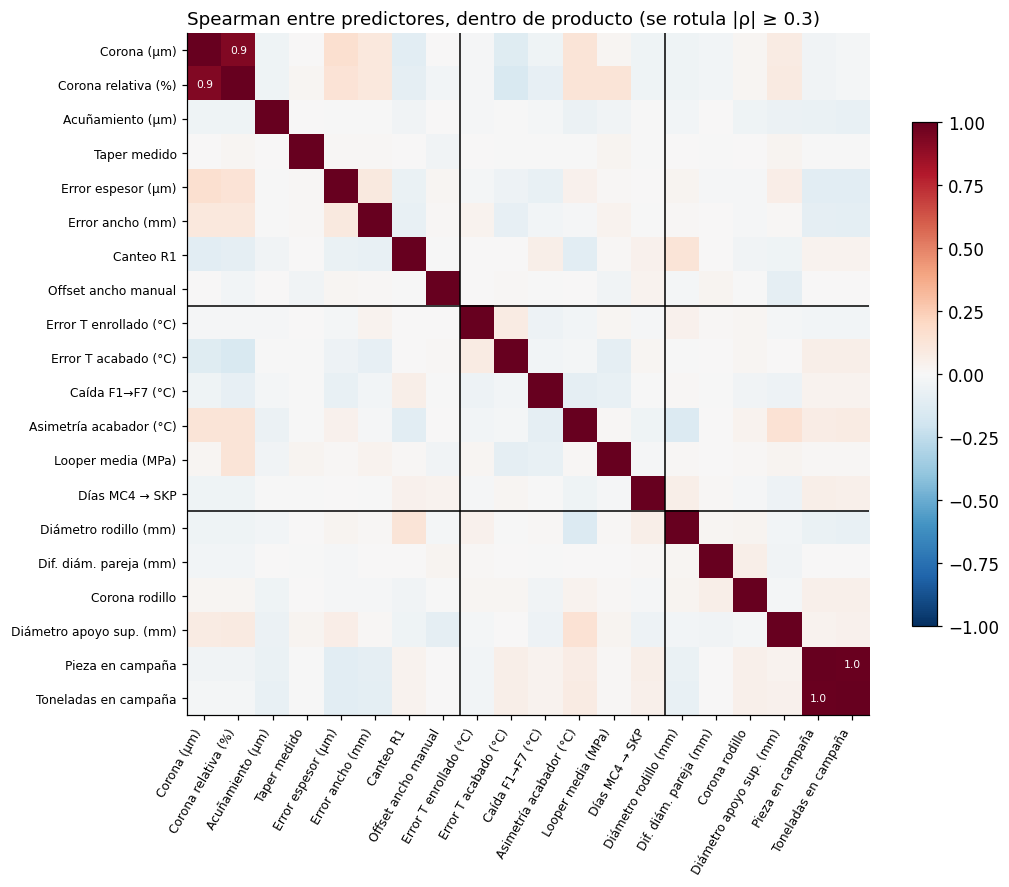

In [6]:
Sp = W[PRED].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(Sp.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(PRED))); ax.set_xticklabels(PRED, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(PRED))); ax.set_yticklabels(PRED, fontsize=8)
for i in range(len(PRED)):
    for j in range(len(PRED)):
        v = Sp.iat[i, j]
        if i != j and abs(v) >= .3:
            ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=7, color='white' if abs(v) > .6 else 'black')
for k in [len(MC4_GEO) - .5, len(MC4_GEO) + len(MC4_TER) - .5]:
    ax.axhline(k, color='k', lw=1); ax.axvline(k, color='k', lw=1)
ax.set_title('Spearman entre predictores, dentro de producto (se rotula |ρ| ≥ 0.3)')
fig.colorbar(im, ax=ax, shrink=.7)
guardar(fig, '02_redundancia'); plt.show()

In [7]:
def vif(df):
    # VIF_j = 1 / (1 - R²_j), con R²_j de regresar la variable j sobre las demás (variables estandarizadas).
    Z = df.dropna(); Z = (Z - Z.mean()) / Z.std()
    out = {}
    for c in Z.columns:
        y = Z[c].values; Xo = np.c_[np.ones(len(Z)), Z.drop(columns=c).values]
        beta, *_ = np.linalg.lstsq(Xo, y, rcond=None)
        r2 = 1 - ((y - Xo @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out, name='VIF'), len(Z)

PRED_VIF = [p for p in PRED if p not in ['Corona (µm)', 'Offset ancho manual']]   # corona absoluta y relativa son la misma señal
v, n_vif = vif(W[PRED_VIF])
print(f'VIF con {n_vif:,} piezas completas (sin Corona absoluta ni Offset manual, que es casi siempre 0):')
v.sort_values(ascending=False).round(2).to_frame().assign(bloque=lambda d: d.index.map(BLOQUE))

VIF con 43,485 piezas completas (sin Corona absoluta ni Offset manual, que es casi siempre 0):


/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_12948/176377248.py:8: RuntimeWarning: divide by zero encountered in matmul
  r2 = 1 - ((y - Xo @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_12948/176377248.py:8: RuntimeWarning: overflow encountered in matmul
  r2 = 1 - ((y - Xo @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_12948/176377248.py:8: RuntimeWarning: invalid value encountered in matmul
  r2 = 1 - ((y - Xo @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_12948/176377248.py:8: RuntimeWarning: divide by zero encountered in matmul
  r2 = 1 - ((y - Xo @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
/var/folders/h4/srr2qc116dg83xvd0rkbfh6c0000gn/T/ipykernel_12948/176377248.py:8: RuntimeWarning: overflow encountered in matmul
  r2 = 1 - ((y - Xo @ beta) ** 2).sum() / ((y - y.mean()) ** 2)

,VIF,bloque
Toneladas en campaña,38.58,SKP rodillos
Pieza en campaña,38.44,SKP rodillos
Error T acabado (°C),3.76,MC4 térmica
Error T enrollado (°C),3.75,MC4 térmica
Diámetro apoyo sup. (mm),1.08,SKP rodillos
Asimetría acabador (°C),1.08,MC4 térmica
Diámetro rodillo (mm),1.07,SKP rodillos
Corona relativa (%),1.06,MC4 geometría
Error espesor (µm),1.05,MC4 geometría
Días MC4 → SKP,1.05,MC4 térmica


**Qué buscamos.**
- **Castillos:** si las temperaturas de castillos vecinos se correlacionan muy alto, usar las 7 como predictores es redundante. Basta un resumen: la caída F1→F7 que propuso la tesis, o una componente principal (sección 9).
- **Pares redundantes** en el mapa: corona absoluta y corona relativa son la misma señal (se usará una); piezas y toneladas en campaña miden el mismo desgaste.
- **VIF:** por encima de ~5 la variable se explica casi entera por las demás y su coeficiente sería inestable en un modelo lineal.

**Qué observamos.**
- **Castillos:** F1, F2 y F3 son casi la misma señal (ρ de 0.94 a 0.96); F5, F6 y F7 forman otro grupo (0.76 a 0.93). F1 y F7 solo comparten ρ = 0.41. El tren tiene **dos partes**: la temperatura de entrada (F1-F4) y el enfriamiento final (F5-F7). Basta con la temperatura en F1 y la caída F1→F7.
- **VIF:** solo dos variables pasan de 5. *Piezas* y *toneladas en campaña* (VIF ≈ 38) son la misma medida de desgaste, así que se usa una. Los errores de temperatura de acabado y de enrollado comparten algo (VIF ≈ 3.8), pero se pueden usar juntos. Todo lo demás tiene VIF cercano a 1.
- **Una vez centradas por producto, las variables casi no son redundantes entre sí.** La multicolinealidad no será problema en los modelos, con las dos excepciones anteriores.

### 4. Herencia del MC4 y operación del Skinpass contra el esfuerzo
Spearman dentro de producto, con intervalo de confianza del 95 % por **bootstrap de programas del MC4** (200 remuestreos). También reportamos Pearson para detectar si la relación es lineal.

In [8]:
progs = W['Programa MC4'].values
codigos, inv = np.unique(progs, return_inverse=True)
filas_de = [np.flatnonzero(inv == k) for k in range(len(codigos))]
Rk = W[RESP + PRED].rank()                         # Spearman = Pearson sobre rangos

def pearson_mask(a, b):
    m = ~(np.isnan(a) | np.isnan(b))
    return np.corrcoef(a[m], b[m])[0, 1] if m.sum() > 30 else np.nan

B = 200
idx_boot = [np.concatenate([filas_de[k] for k in rng.integers(0, len(codigos), len(codigos))]) for _ in range(B)]
filas = []
for r in ['ΔBending', 'ΔFuerza', 'Bending real', 'Fuerza real']:
    y_all = Rk[r].values
    for p in PRED:
        x_all = Rk[p].values
        boots = [pearson_mask(x_all[i], y_all[i]) for i in idx_boot]
        filas.append({'respuesta': r, 'predictor': p, 'bloque': BLOQUE[p],
                      'spearman': pearson_mask(x_all, y_all),
                      'ic_bajo': np.nanpercentile(boots, 2.5), 'ic_alto': np.nanpercentile(boots, 97.5),
                      'pearson': corr_par(W, p, r, 'pearson'), 'n': int((~np.isnan(x_all) & ~np.isnan(y_all)).sum())})
asoc = pd.DataFrame(filas)
asoc['excluye_0'] = (asoc.ic_bajo > 0) | (asoc.ic_alto < 0)
asoc.round(3).to_csv(RESULTADOS / '02_asociaciones_dentro_producto.csv', index=False)
(asoc[asoc.respuesta.isin(['ΔBending', 'ΔFuerza'])]
 .assign(absr=lambda d: d.spearman.abs()).sort_values(['respuesta', 'absr'], ascending=[True, False])
 .drop(columns='absr').round(3).groupby('respuesta').head(8))

,respuesta,predictor,bloque,spearman,ic_bajo,ic_alto,pearson,n,excluye_0
13,ΔBending,Días MC4 → SKP,MC4 térmica,0.052,0.038,0.068,0.026,48296,True
15,ΔBending,Dif. diám. pareja (mm),SKP rodillos,-0.040,-0.058,-0.024,-0.009,47225,True
7,ΔBending,Offset ancho manual,MC4 geometría,-0.036,-0.047,-0.023,-0.003,48142,True
0,ΔBending,Corona (µm),MC4 geometría,-0.036,-0.049,-0.022,-0.015,46397,True
18,ΔBending,Pieza en campaña,SKP rodillos,0.023,0.007,0.037,-0.006,48296,True
19,ΔBending,Toneladas en campaña,SKP rodillos,0.023,0.007,0.037,-0.009,48296,True
1,ΔBending,Corona relativa (%),MC4 geometría,-0.021,-0.034,-0.009,-0.013,46397,True
3,ΔBending,Taper medido,MC4 geometría,0.016,0.006,0.029,-0.003,46675,True
33,ΔFuerza,Días MC4 → SKP,MC4 térmica,0.228,0.211,0.245,0.095,48296,True
38,ΔFuerza,Pieza en campaña,SKP rodillos,0.185,0.168,0.201,0.095,48296,True


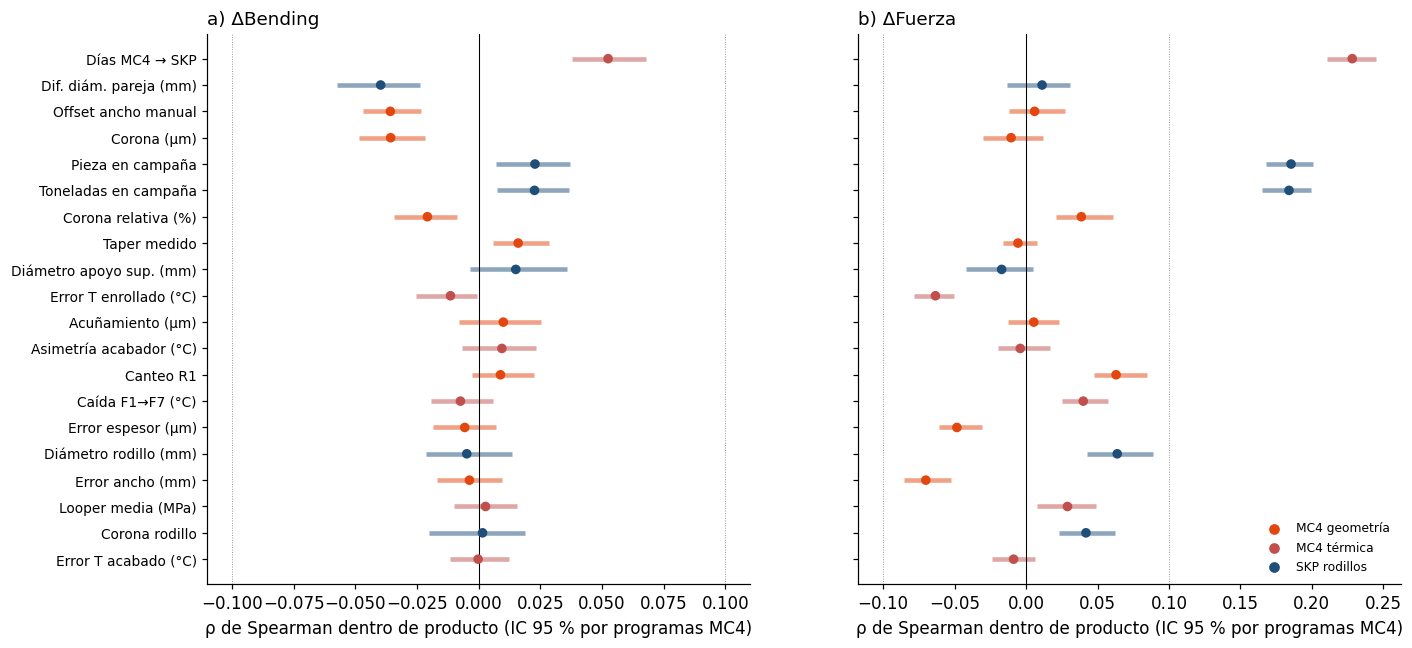

In [9]:
COL_B = {'MC4 geometría': COLORES['naranja'], 'MC4 térmica': COLORES['rojo'], 'SKP rodillos': COLORES['azul']}
fig, ax = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
orden = asoc[asoc.respuesta == 'ΔBending'].set_index('predictor').spearman.abs().sort_values().index
for k, r in enumerate(['ΔBending', 'ΔFuerza']):
    d = asoc[asoc.respuesta == r].set_index('predictor').loc[orden]
    y = np.arange(len(d))
    ax[k].hlines(y, d.ic_bajo, d.ic_alto, color=[COL_B[b] for b in d.bloque], lw=3, alpha=.5)
    ax[k].scatter(d.spearman, y, color=[COL_B[b] for b in d.bloque], zorder=3, s=28)
    ax[k].axvline(0, color='k', lw=.7)
    for x0 in (-.1, .1): ax[k].axvline(x0, color=COLORES['gris'], lw=.6, ls=':')
    ax[k].set_yticks(y); ax[k].set_yticklabels(d.index, fontsize=9)
    ax[k].set_xlabel('ρ de Spearman dentro de producto (IC 95 % por programas MC4)')
    ax[k].set_title(f'{"ab"[k]}) {r}')
for b, c in COL_B.items(): ax[1].scatter([], [], color=c, label=b)
ax[1].legend(fontsize=8, loc='lower right')
guardar(fig, '02_asociaciones'); plt.show()

**Cómo leer la gráfica.** Cada punto es la correlación de un predictor con la respuesta, comparando piezas del mismo producto. La barra es el intervalo de confianza del 95 %. Si la barra no toca el 0, la asociación es distinguible del ruido. Las líneas punteadas en ±0.1 marcan un tamaño a partir del cual la asociación empieza a ser relevante en la práctica (explicaría ~1 % de la varianza por sí sola).

**Qué observamos. Este es el resultado central del notebook.**
- **Ninguna variable de la herencia del MC4 se asocia de forma relevante con ΔBending.** La asociación más fuerte es |ρ| = 0.05 (días entre MC4 y Skinpass); la corona llega a −0.04. Muchas son distinguibles de cero (con 48 mil piezas casi todo lo es), pero **todas están por debajo de 0.1**.
- **ΔFuerza sí tiene asociaciones de tamaño moderado:**
  - **Días MC4 → SKP:** ρ = 0.23 (IC 0.21 a 0.25). La relación no es lineal (Pearson solo 0.10).
  - **Piezas en campaña:** ρ = 0.19. La sección 7 muestra que esta es sobre todo un efecto del ancho.
  - El resto (error de ancho, diámetro del rodillo, error de enrollado, canteo R1) queda entre 0.05 y 0.07.

**Cómo interpretarlo.** ΔBending varía mucho dentro de producto (Notebook 01), pero esa variación **no viene de la herencia del MC4**, al menos no de forma directa ni monótona. Lo que el Notebook 01 encontró es que la explican en parte el turno y la campaña de rodillo (~21 %): es una variación de la **operación del Skinpass**. Esto ya es una respuesta parcial a la pregunta de la tesis.

**Qué no podemos afirmar.** Que el MC4 no influya en el bending. Una correlación marginal puede esconder un efecto que aparece solo en combinación con otras variables (interacciones) o en ciertos productos. Eso lo prueba el modelo multivariado del Notebook 04.

### 5. Forma de la relación
Para los predictores con mayor asociación: media de ΔBending (dentro de producto) por decil del predictor (dentro de producto). Una línea recta indica relación lineal; una curva o un escalón, no linealidad o umbral.

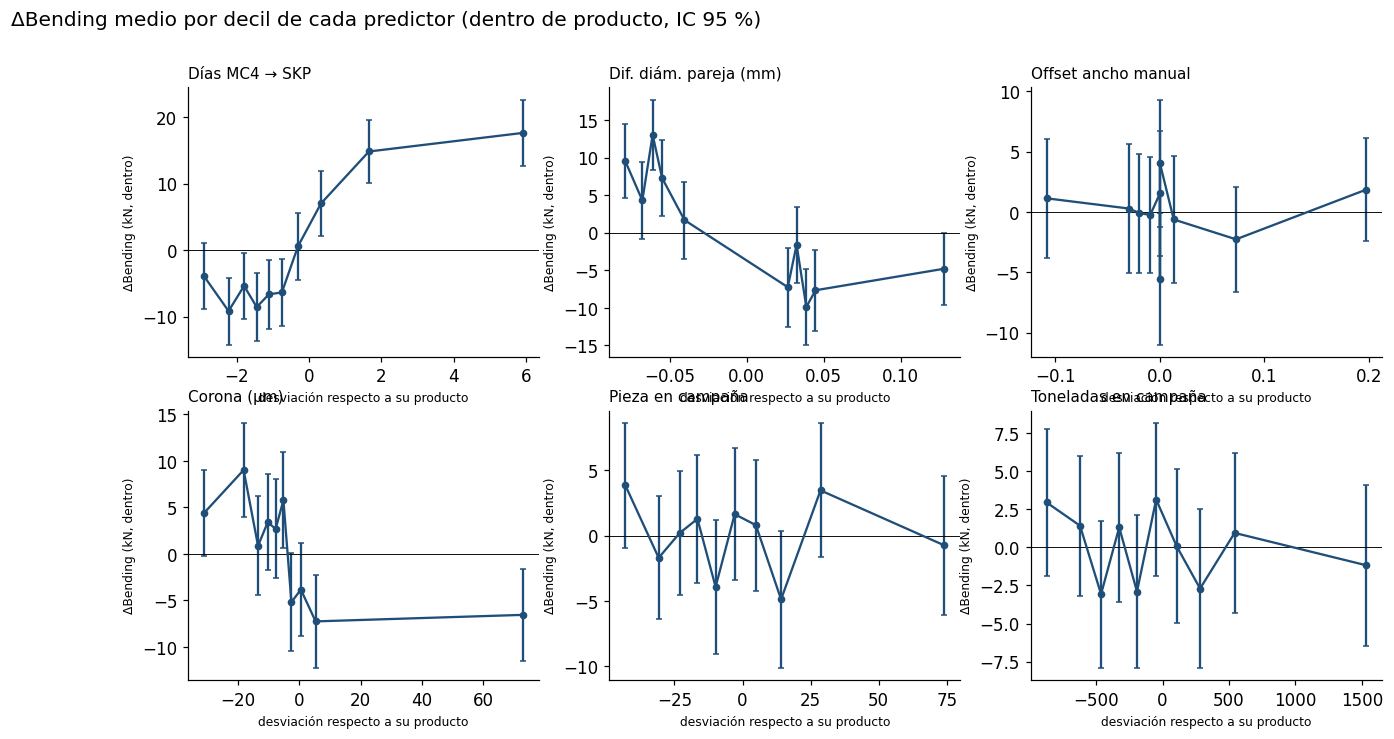

In [10]:
top = (asoc[asoc.respuesta == 'ΔBending'].assign(a=lambda d: d.spearman.abs())
       .sort_values('a', ascending=False).predictor.head(6).tolist())
fig, ax = plt.subplots(2, 3, figsize=(14, 7)); ax = ax.ravel()
for i, p in enumerate(top):
    d = W[[p, 'ΔBending', 'ΔFuerza']].dropna()
    q = pd.qcut(d[p].rank(method='first'), 10, labels=False)
    g = d.groupby(q).agg(x=(p, 'median'), yb=('ΔBending', 'mean'), yf=('ΔFuerza', 'mean'),
                         se=('ΔBending', lambda s: s.std() / np.sqrt(len(s))))
    ax[i].errorbar(g.x, g.yb, yerr=1.96 * g.se, fmt='o-', color=COLORES['azul'], ms=4, capsize=2)
    ax[i].axhline(0, color='k', lw=.6)
    ax[i].set_title(p, fontsize=10); ax[i].set_xlabel('desviación respecto a su producto', fontsize=8)
    ax[i].set_ylabel('ΔBending (kN, dentro)', fontsize=8)
fig.suptitle('ΔBending medio por decil de cada predictor (dentro de producto, IC 95 %)', x=.01, ha='left')
guardar(fig, '02_forma_relacion'); plt.show()

**Qué observamos.** Las relaciones existen pero son pequeñas frente a la dispersión de ΔBending (rango intercuartílico de 150 kN):
- **Días MC4 → SKP:** escalón. Las piezas que esperan menos que lo normal para su producto tienen ΔBending ~−8 kN; las que esperan más, hasta +18 kN.
- **Corona:** las piezas con más corona que lo normal tienen ΔBending ~−7 kN; las de menos corona, ~+5 kN. Es el sentido físico esperado (el bending compensa la corona), pero de solo ~12 kN de punta a punta.
- **Diferencia de diámetro entre pareja de rodillos:** más diferencia, ΔBending algo menor.
- **Posición en la campaña:** plana.

**¿Los días de espera son una trampa?** Podría ser que los rollos retenidos para revisión en el MC4 tarden más en llegar al Skinpass. Lo revisamos:

In [11]:
b2 = base.assign(dict_mc4=Lb['Dictamen MC4'].values)
filas = []
for g in ['ACEPTADO', 'RETENIDO']:
    m = b2['dict_mc4'] == g
    filas.append({'dictamen en MC4': g, 'piezas': int(m.sum()), 'días mediana': b2.loc[m, 'Días MC4 → SKP'].median(),
                  'ρ días-ΔFuerza (dentro)': W.loc[m, 'Días MC4 → SKP'].corr(W.loc[m, 'ΔFuerza'], method='spearman'),
                  'ρ días-ΔBending (dentro)': W.loc[m, 'Días MC4 → SKP'].corr(W.loc[m, 'ΔBending'], method='spearman')})
pd.DataFrame(filas).round(3)

,dictamen en MC4,piezas,días mediana,ρ días-ΔFuerza (dentro),ρ días-ΔBending (dentro)
0,ACEPTADO,19975,5.203,0.243,0.056
1,RETENIDO,28351,5.168,0.219,0.050


**Resultado.** No es eso: aceptados y retenidos en el MC4 esperan lo mismo (mediana 5.2 días) y la asociación con ΔFuerza es igual en los dos grupos (0.24 y 0.22). El tiempo de espera es una **señal propia**. Hay dos explicaciones posibles que el Notebook 04 tendrá que separar:
- **Física:** el acero sigue cambiando después de laminado (envejecimiento, enfriamiento completo del rollo), y un rollo que espera más llega más duro.
- **Logística:** los rollos que esperan más pueden ser los que no encontraron orden, y esos son distintos de otra forma.

### 6. ¿El esfuerzo y la herencia se asocian con los defectos?
Para cada resultado B, diferencia estandarizada de medias (dentro de producto) entre piezas con el evento y piezas sin él. Es la primera revisión de la **cadena del mediador**: para que el sobreesfuerzo medie entre el MC4 y el defecto, el esfuerzo tiene que asociarse con el defecto y la herencia con el esfuerzo.

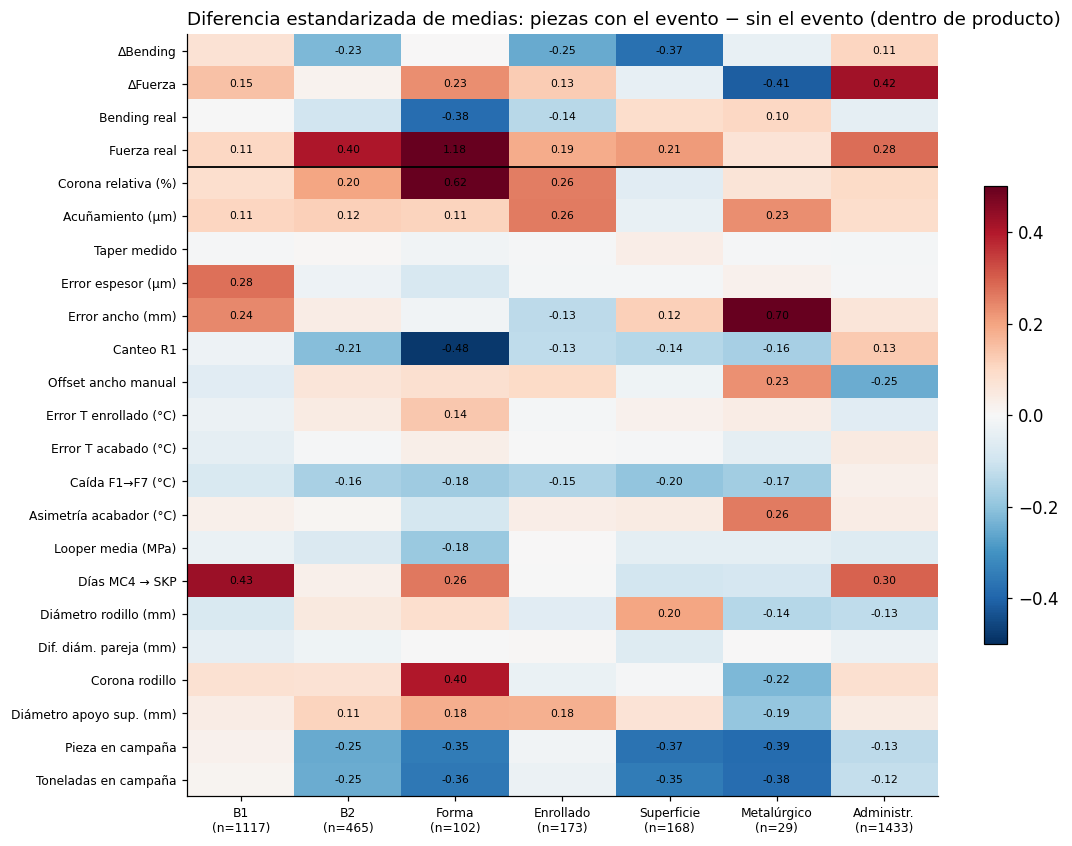

In [12]:
EVENTOS = ['B1', 'B2', 'B2 · Forma', 'B2 · Enrollado', 'B2 · Superficie y manejo', 'B2 · Metalúrgico (acería / MC4)', 'Administrativa']
VARS_B = RESP + [p for p in PRED if p != 'Corona (µm)']
sd = W[VARS_B].std()
smd = pd.DataFrame({e: (W.loc[base[e], VARS_B].mean() - W.loc[~base[e], VARS_B].mean()) / sd for e in EVENTOS})
eventos_n = base[EVENTOS].sum()
CORTO = {'B2 · Forma': 'Forma', 'B2 · Enrollado': 'Enrollado', 'B2 · Superficie y manejo': 'Superficie',
         'B2 · Metalúrgico (acería / MC4)': 'Metalúrgico', 'Administrativa': 'Administr.'}
smd.columns = [f'{CORTO.get(e, e)}\n(n={eventos_n[e]})' for e in EVENTOS]
smd.round(2).to_csv(RESULTADOS / '02_defectos_smd.csv')

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(smd.values, cmap='RdBu_r', vmin=-.5, vmax=.5, aspect='auto')
ax.set_xticks(range(smd.shape[1])); ax.set_xticklabels(smd.columns, fontsize=8)
ax.set_yticks(range(smd.shape[0])); ax.set_yticklabels(smd.index, fontsize=8)
for i in range(smd.shape[0]):
    for j in range(smd.shape[1]):
        v = smd.iat[i, j]
        if abs(v) >= .1: ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7)
ax.axhline(len(RESP) - .5, color='k', lw=1.2)
ax.set_title('Diferencia estandarizada de medias: piezas con el evento − sin el evento (dentro de producto)')
fig.colorbar(im, ax=ax, shrink=.6)
guardar(fig, '02_defectos'); plt.show()

**Cómo leerlo.** Rojo: las piezas con el evento tienen valores **más altos** que lo normal para su producto; azul, más bajos. Arriba de la línea negra están las respuestas del esfuerzo (la parte "mediador" de la cadena); abajo, la herencia del MC4 y la operación del Skinpass. Se rotulan diferencias de al menos 0.1 desviaciones estándar.

**Cuidado con los eventos pequeños.** Con 50-150 eventos, una diferencia de 0.2 puede ser ruido. Se toma como pista para el Notebook 05, no como resultado.

**Qué observamos.**
- **Forma (102 piezas) muestra la cadena más clara.** Comparadas con piezas de su mismo producto, las piezas con defecto de forma llegaron con **más corona relativa (+0.62 DE)** y se laminaron con **mucha más fuerza real (+1.18 DE)**. También tenían menos canteo R1 (−0.48), un rodillo con más corona (+0.40) y estaban al inicio de la campaña (−0.35). Su ΔFuerza apenas es mayor (+0.23): **el preset ya anticipaba esa fuerza alta**. Si hay un mediador, para los defectos de forma pasa por la **fuerza real**, no por la desviación del bending.
- **Superficie (168) y enrollado (173)** tienen ΔBending menor que lo normal (−0.37 y −0.25). Superficie ocurre al inicio de la campaña (−0.37): un rodillo recién montado podría marcar la lámina.
- **B1 (1,117) y administrativa** esperaron más días entre líneas (+0.43 y +0.30). Es esperable que una pieza con problema de orden espere más: aquí los días pueden ser **consecuencia**, no causa. B1 también tiene más error de espesor (+0.28) y de ancho (+0.24), lo esperado si la regla compara esas mediciones.
- **Metalúrgico** (29 piezas) tiene un error de ancho muy alto (+0.70), pero con tan pocos eventos no se interpreta.

**Implicación.** La pregunta del mediador cambia de forma: en lugar de *MC4 → ΔBending → defecto*, los datos sugieren **corona del MC4 → fuerza real del Skinpass → defecto de forma**. El Notebook 06 debe probar ese camino.

### 7. La subida de ΔFuerza en la campaña, ¿es el ancho?
Pregunta pendiente del Notebook 01. Dentro de una campaña los programas suelen ordenar los anchos (de ancho a angosto). Si el ancho cambia con la posición y la fuerza depende del ancho, la "señal de desgaste" podría ser solo el orden de programación. Comparamos la curva centrando por producto y por **producto × rango de ancho**.

Spearman entre posición en campaña y ancho (dentro de producto): -0.515


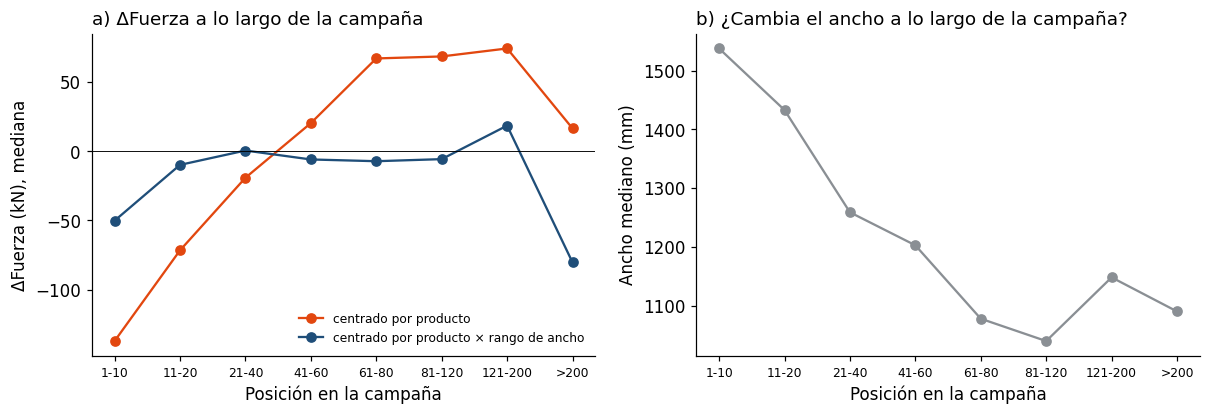

In [13]:
base['Rango ancho'] = pd.cut(base['Ancho (mm)'], [0, 1000, 1150, 1300, 1450, 1600, 3000]).astype(str)
base['Prod×Ancho'] = base['Producto'] + ' | ' + base['Rango ancho']
base['tramo'] = pd.cut(base['Pieza en campaña'], [0, 10, 20, 40, 60, 80, 120, 200, 2000],
                       labels=['1-10', '11-20', '21-40', '41-60', '61-80', '81-120', '121-200', '>200'])
print(f"Spearman entre posición en campaña y ancho (dentro de producto): {corr_par(W.assign(p=W['Pieza en campaña']), 'p', 'Ancho (mm)', 'spearman'):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for g, c, lab in [('Producto', COLORES['naranja'], 'centrado por producto'),
                  ('Prod×Ancho', COLORES['azul'], 'centrado por producto × rango de ancho')]:
    y = base['ΔFuerza'] - base.groupby(g)['ΔFuerza'].transform('mean')
    m = y.groupby(base['tramo'], observed=True).median()
    ax[0].plot(range(len(m)), m.values, 'o-', color=c, label=lab)
ax[0].set_xticks(range(len(m))); ax[0].set_xticklabels(m.index, fontsize=8); ax[0].axhline(0, color='k', lw=.6)
ax[0].set_xlabel('Posición en la campaña'); ax[0].set_ylabel('ΔFuerza (kN), mediana'); ax[0].legend(fontsize=8)
ax[0].set_title('a) ΔFuerza a lo largo de la campaña')
a = base.groupby('tramo', observed=True)['Ancho (mm)'].median()
ax[1].plot(range(len(a)), a.values, 'o-', color=COLORES['gris'])
ax[1].set_xticks(range(len(a))); ax[1].set_xticklabels(a.index, fontsize=8)
ax[1].set_xlabel('Posición en la campaña'); ax[1].set_ylabel('Ancho mediano (mm)')
ax[1].set_title('b) ¿Cambia el ancho a lo largo de la campaña?')
guardar(fig, '02_campana_ancho'); plt.show()

**Cómo interpretarlo.** Si la curva azul (que ya compara piezas del mismo producto y del mismo rango de ancho) conserva la subida, el ancho no la explica y la señal de desgaste se mantiene como hipótesis para el Notebook 07. Si la subida desaparece, era el orden de programación.

**Qué observamos. Esto corrige el Notebook 01.**
- El ancho **baja con fuerza** a lo largo de la campaña: de ~1,540 mm en las primeras piezas a ~1,040 mm después de la pieza 80 (ρ = −0.52 dentro de producto). Es la forma de "ataúd" del programa: primero lo ancho, después lo angosto.
- Al comparar piezas del mismo producto **y del mismo rango de ancho** (azul), la subida de ΔFuerza casi desaparece: de −135 → +70 kN pasa a −50 → ~0 kN, plana después de la pieza 20.

**Conclusión.** La "señal de desgaste" del Notebook 01 era **sobre todo el orden de anchos del programa**. Queda un efecto residual pequeño en las primeras 10 piezas (~−50 kN), compatible con un rodillo recién montado. El experimento natural de desgaste (Notebook 07) sigue siendo posible, pero **siempre controlando por ancho**, y con una expectativa de efecto mucho menor.

### 8. Hallazgo aparte: el sesgo del preset de fuerza por producto
El 84 % de la varianza de ΔFuerza es entre productos. Documentamos qué productos tienen el sesgo más grande y si se relaciona con características simples del producto.

In [14]:
pp = base.groupby('Producto').agg(piezas=('ΔFuerza', 'size'), dF_mediana=('ΔFuerza', 'median'),
                                  dF_RIC=('ΔFuerza', lambda s: s.quantile(.75) - s.quantile(.25)),
                                  espesor=('Espesor (mm)', 'median'), ancho=('Ancho (mm)', 'median'))
pp['preset_mediano'] = Lb.groupby(base['Producto'])[PF].median()
pp['sesgo_%'] = 100 * pp.dF_mediana / pp.preset_mediano
grandes = pp[pp.piezas >= 200].sort_values('dF_mediana')
grandes.round(1).to_csv(RESULTADOS / '02_sesgo_preset_fuerza_por_producto.csv')
print(f"Productos con ≥ 200 piezas: {len(grandes)} · cubren {grandes.piezas.sum() / len(base):.0%} de las piezas")
print(f"Sesgo relativo (ΔFuerza / preset), mediana entre productos: {grandes['sesgo_%'].median():.1f} % · rango p10-p90: "
      f"{grandes['sesgo_%'].quantile(.1):.1f} % a {grandes['sesgo_%'].quantile(.9):.1f} %")
print(f"Spearman entre sesgo relativo y espesor del producto: {grandes['sesgo_%'].corr(grandes.espesor, method='spearman'):.2f}")
print(f"Spearman entre sesgo relativo y ancho del producto:   {grandes['sesgo_%'].corr(grandes.ancho, method='spearman'):.2f}")
pd.concat([grandes.head(5), grandes.tail(5)])[['piezas', 'dF_mediana', 'dF_RIC', 'preset_mediano', 'sesgo_%', 'espesor']].round(0)

Productos con ≥ 200 piezas: 68 · cubren 65% de las piezas
Sesgo relativo (ΔFuerza / preset), mediana entre productos: -18.1 % · rango p10-p90: -32.0 % a 13.9 %
Spearman entre sesgo relativo y espesor del producto: -0.43
Spearman entre sesgo relativo y ancho del producto:   -0.01


,piezas,dF_mediana,dF_RIC,preset_mediano,sesgo_%,espesor
Producto,,,,,,
"TER | 80LWSI | (2.0, 2.5]",269,-3120.0,618.0,7754.0,-40.0,2.0
"SAE J2340 | APM80G | (3.0, 4.0]",312,-3050.0,471.0,7614.0,-40.0,3.0
"ASME SA 414 | T16LA5 | (4.0, 5.0]",435,-2865.0,668.0,7201.0,-40.0,4.0
"GMW3032M-ST-S | APM80G | (4.0, 5.0]",431,-2607.0,329.0,7398.0,-35.0,4.0
"SAE J2340 | APM80M | (3.0, 4.0]",224,-2562.0,475.0,6641.0,-39.0,3.0
"ASTM A 1011 | APM55G | (1.5, 2.0]",256,713.0,582.0,3470.0,21.0,2.0
"TER | C091TM | (1.5, 2.0]",841,1210.0,690.0,3801.0,32.0,2.0
"SAE J403 | C091TM | (1.5, 2.0]",1151,1221.0,677.0,4290.0,28.0,2.0
"ASTM A 572 | APM55G | (1.5, 2.0]",405,1316.0,915.0,3491.0,38.0,2.0


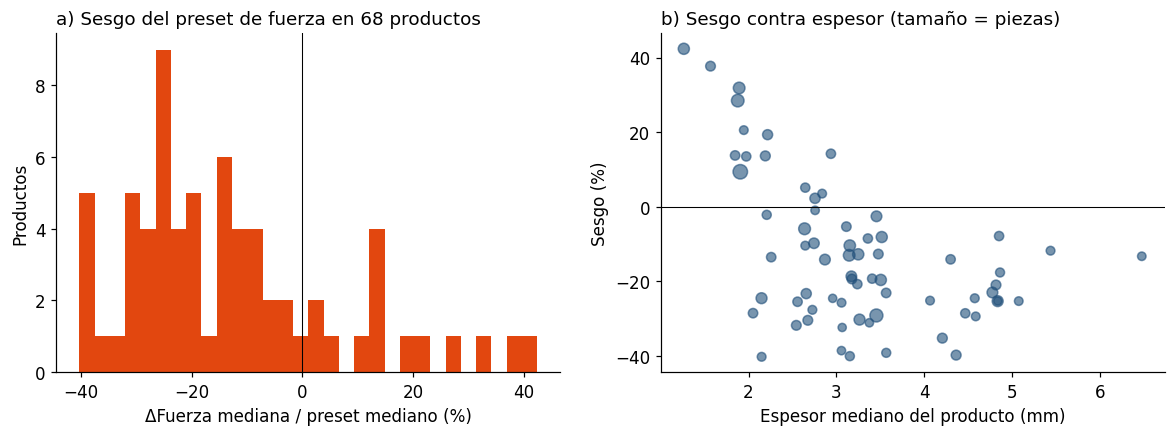

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(grandes['sesgo_%'], 30, color=COLORES['naranja'])
ax[0].axvline(0, color='k', lw=.7); ax[0].set_xlabel('ΔFuerza mediana / preset mediano (%)'); ax[0].set_ylabel('Productos')
ax[0].set_title(f'a) Sesgo del preset de fuerza en {len(grandes)} productos')
ax[1].scatter(grandes.espesor, grandes['sesgo_%'], s=np.sqrt(grandes.piezas) * 2, color=COLORES['azul'], alpha=.6)
ax[1].axhline(0, color='k', lw=.7); ax[1].set_xlabel('Espesor mediano del producto (mm)'); ax[1].set_ylabel('Sesgo (%)')
ax[1].set_title('b) Sesgo contra espesor (tamaño = piezas)')
guardar(fig, '02_sesgo_producto'); plt.show()

**Qué observamos.**
- En los 68 productos con al menos 200 piezas (65 % de la producción), el preset de fuerza se equivoca en mediana un **−18 %**: la fuerza real queda por debajo de lo previsto. Pero el sesgo va de **−32 % a +14 %** entre productos (p10 a p90).
- **El sesgo depende del espesor** (ρ = −0.43). En lámina delgada el preset **subestima** la fuerza: SAE J403 C071TM de ~1 mm, +42 %; C091TM de ~2 mm, +28 % a +32 %. En lámina más gruesa y de alta resistencia la **sobreestima**: APM80G, 80LWSI y T16LA5, cerca de −40 %. No depende del ancho.
- Dentro de cada producto el error es estable (rango intercuartílico de 300 a 900 kN, contra sesgos de hasta 3,000 kN).
- Varios productos se acumulan justo en **−40 %**. Podría ser un límite del modelo de setup (la fuerza real no baja de 60 % del preset) más que un error natural. Conviene revisarlo antes de proponer la recalibración.

**Cómo interpretarlo.** El modelo de setup tiene un error **sistemático y predecible por producto**. Corregirlo no requiere entender el MC4: bastaría ajustar el preset con la mediana histórica de cada producto. Queda como **intervención candidata D: recalibración del preset de fuerza por producto**.

**Qué no podemos afirmar.** Que un preset más preciso mejore la calidad. Primero hay que mostrar que el error del preset se asocia con defectos (Notebooks 05-06). También puede ser que el setup sobreestime a propósito en aceros de alta resistencia, como margen de seguridad.

### 9. ¿Vale la pena el PCA por bloque?
Aplicamos PCA a tres bloques, con variables **centradas por producto y estandarizadas**:
- **MC4 térmica:** las 7 temperaturas de castillo, acabado y enrollado reales, acabador superior A y B, temperatura de descarga, tiempo de estancia, tiempo R2→F1, cubierta térmica y las 6 tensiones de looper.
- **MC4 geometría:** corona relativa, acuñamiento, taper, errores de espesor y ancho, canteo R1 y R2.
- **SKP rodillos:** diámetros, diferencia entre pareja, corona del rodillo, piezas y toneladas en campaña.

Criterio para adoptarlo: (1) pocas componentes capturan buena parte de la varianza **y** (2) las componentes se asocian con ΔBending al menos tanto como la mejor variable original del bloque.

In [16]:
TERM = [M(c) for c in castillos] + [M(c) for c in ['Temp Acabado Real', 'Temp Enrollado Real', 'Temp. Acabador Sup. A',
        'Temp. Acabador Sup. B', 'Temperatura Descarga Salida', 'Tiempo Estancia', 'Tiempo Entre Salida R2 y Entrada F1',
        '% Uso Cubierta Térmica']] + [M(f'Tensión de Looper {i} [Mpa]') for i in range(1, 7)]
GEO = {'Corona relativa (%)': base['Corona relativa (%)'], 'Acuñamiento (µm)': base['Acuñamiento (µm)'],
       'Taper medido': base['Taper medido'], 'Error espesor (µm)': base['Error espesor (µm)'],
       'Error ancho (mm)': base['Error ancho (mm)'], 'Canteo R1': base['Canteo R1'], 'Canteo R2': Lb[M('Canteo R2')]}
BLOQUES_PCA = {
    'MC4 térmica': pd.DataFrame({c.replace(' MC4', ''): pd.to_numeric(Lb[c], errors='coerce') for c in TERM}),
    'MC4 geometría': pd.DataFrame(GEO),
    'SKP rodillos': base[SKP_OP].copy(),
}
pca_res = {}
for nombre, df in BLOQUES_PCA.items():
    df = df.copy(); df['Producto'] = base['Producto']
    Z = dentro(df, [c for c in df.columns if c != 'Producto']).dropna()
    Z = Z.loc[:, Z.std() > 0]; Z = (Z - Z.mean()) / Z.std()
    p = PCA().fit(Z)
    comps = pd.DataFrame(p.transform(Z)[:, :3], index=Z.index, columns=['PC1', 'PC2', 'PC3'])
    yb = W.loc[Z.index, 'ΔBending']
    rho_pc = comps.apply(lambda c: c.corr(yb, method='spearman'))
    rho_orig = Z.apply(lambda c: c.corr(yb, method='spearman'))
    pca_res[nombre] = dict(p=p, cols=Z.columns, n=len(Z), rho_pc=rho_pc, rho_orig=rho_orig,
                           cargas=pd.DataFrame(p.components_[:3].T, index=Z.columns, columns=['PC1', 'PC2', 'PC3']))
    var = p.explained_variance_ratio_
    print(f"{nombre}: {len(Z.columns)} variables, {len(Z):,} piezas · varianza PC1 {var[0]:.0%}, PC1-3 {var[:3].sum():.0%} · "
          f"|ρ| con ΔBending: mejor PC {rho_pc.abs().max():.3f} ({rho_pc.abs().idxmax()}), mejor variable {rho_orig.abs().max():.3f} ({rho_orig.abs().idxmax()})")

/Users/diego/.pyenv/versions/3.9.13/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/diego/.pyenv/versions/3.9.13/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/diego/.pyenv/versions/3.9.13/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T
/Users/diego/.pyenv/versions/3.9.13/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/diego/.pyenv/versions/3.9.13/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/diego/.pyenv/versions/3.9.13/lib/pyt

MC4 térmica: 21 variables, 45,781 piezas · varianza PC1 30%, PC1-3 56% · |ρ| con ΔBending: mejor PC 0.024 (PC1), mejor variable 0.030 (Tensión de Looper 1 [Mpa])
MC4 geometría: 7 variables, 44,864 piezas · varianza PC1 20%, PC1-3 50% · |ρ| con ΔBending: mejor PC 0.019 (PC2), mejor variable 0.021 (Corona relativa (%))
SKP rodillos: 6 variables, 47,253 piezas · varianza PC1 34%, PC1-3 72% · |ρ| con ΔBending: mejor PC 0.024 (PC3), mejor variable 0.040 (Dif. diám. pareja (mm))


/Users/diego/.pyenv/versions/3.9.13/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/diego/.pyenv/versions/3.9.13/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/diego/.pyenv/versions/3.9.13/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


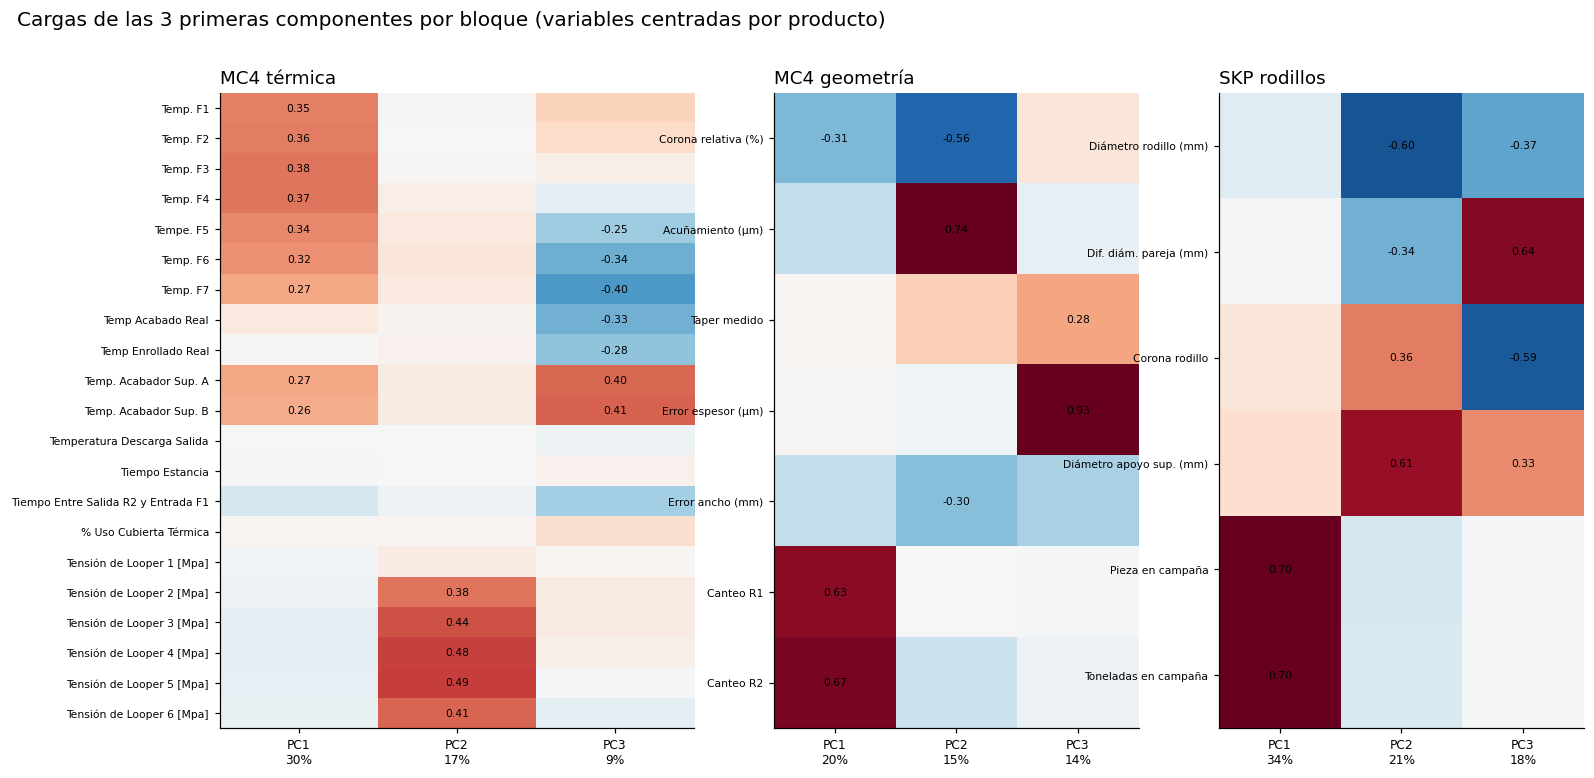

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 7.5), gridspec_kw={'width_ratios': [1.3, 1, 1]})
for k, (nombre, r) in enumerate(pca_res.items()):
    c = r['cargas']
    im = ax[k].imshow(c.values, cmap='RdBu_r', vmin=-.7, vmax=.7, aspect='auto')
    ax[k].set_yticks(range(len(c))); ax[k].set_yticklabels(c.index, fontsize=7)
    ev = r['p'].explained_variance_ratio_[:3]
    ax[k].set_xticks(range(3)); ax[k].set_xticklabels([f'PC{i + 1}\n{ev[i]:.0%}' for i in range(3)], fontsize=8)
    for i in range(len(c)):
        for j in range(3):
            if abs(c.iat[i, j]) >= .25: ax[k].text(j, i, f'{c.iat[i, j]:.2f}', ha='center', va='center', fontsize=7)
    ax[k].set_title(nombre)
fig.suptitle('Cargas de las 3 primeras componentes por bloque (variables centradas por producto)', x=.01, ha='left')
guardar(fig, '02_pca_cargas'); plt.show()

**Cómo leer las cargas.** Cada columna es una componente; cada celda, cuánto pesa una variable en ella. Si una componente tiene todas las cargas del mismo signo en las temperaturas de castillo, representa "el rollo vino más caliente o más frío en todo el tren". Si tiene signos opuestos entre los primeros y los últimos castillos, representa "se enfrió más rápido". El porcentaje bajo cada componente es la varianza del bloque que captura.

**Qué observamos.**
- **MC4 térmica (21 variables):** la PC1 captura el 30 % de la varianza y las tres primeras el 56 %. La PC1 es la "temperatura general del tren" (castillos con el mismo signo). Para resumir 21 variables, no es una compresión fuerte.
- **MC4 geometría (7 variables):** la PC1 solo captura el 20 %. Las variables geométricas casi no comparten información: **no hay nada que resumir**.
- **SKP rodillos (6 variables):** la PC1 captura el 34 %, dominada por piezas y toneladas en campaña, que ya sabemos que son la misma medida.
- **Ninguna componente se asocia con ΔBending más que la mejor variable original de su bloque** (0.024 contra 0.030 en térmica, 0.019 contra 0.021 en geometría, 0.024 contra 0.040 en rodillos).

**Decisión: no usar PCA en los modelos.** No comprime bien, no mejora la asociación con la respuesta y cuesta interpretabilidad. En su lugar se usan resúmenes con significado físico: temperatura en F1, caída F1→F7, una sola medida de desgaste y corona relativa. El PCA queda como herramienta exploratoria (las cargas confirman los dos grupos de castillos).

## F. Conclusiones de la etapa

### Hallazgos principales
1. **El producto confunde casi todo.** Correlaciones crudas de hasta −0.42 se vuelven ~0 al comparar piezas del mismo producto.
2. **La herencia del MC4 casi no se asocia con ΔBending** dentro de producto (todas |ρ| < 0.06). La variación de ΔBending es sobre todo de la **operación del Skinpass** (turno y campaña).
3. **ΔFuerza se asocia con los días de espera entre líneas** (ρ = 0.23), y no por la retención en el MC4. Es una señal nueva que la propuesta no priorizaba.
4. **La "señal de desgaste" del Notebook 01 era el orden de anchos del programa.** Al controlar por ancho queda solo un efecto pequeño en las primeras 10 piezas.
5. **Defectos de forma:** se asocian con **más corona relativa** y **mucha más fuerza real**, no con ΔBending. El camino a probar es corona → fuerza real → forma.
6. **El preset de fuerza tiene un sesgo sistemático por producto** (de −32 % a +14 %, ligado al espesor). Se agrega como **intervención candidata D**.
7. **Multicolinealidad baja** una vez centrado por producto. Sobran F2-F4 (redundantes con F1) y una de piezas/toneladas en campaña.
8. **PCA no aporta** y no se usa en los modelos.

### Decisiones tomadas
| Tema | Decisión |
|---|---|
| Correlaciones | Siempre dentro de producto; las crudas no se interpretan |
| Temperaturas de castillo | Se resumen con T en F1 y caída F1→F7 |
| Desgaste | Una sola medida (piezas en campaña), siempre con el ancho como control |
| PCA | No se usa en modelos; solo exploratorio |
| Mediador | Además de ΔBending, probar **fuerza real** como mediador para defectos de forma |
| Días MC4 → SKP | Entra al bloque MC4 como variable de interés, con cuidado de no usarla para B1 o administrativa (puede ser consecuencia) |
| Intervención D | Recalibración del preset de fuerza por producto, candidata nueva |

### Limitaciones
- Las correlaciones son marginales: no controlan por las demás variables, el turno ni el rodillo. Eso lo hace el Notebook 04.
- Los defectos de B2 tienen pocos eventos; sus diferencias son pistas.
- Centrar por producto quita el promedio, pero no las diferencias de pendiente entre productos.

### Preguntas pendientes
- ¿Un modelo con todas las variables a la vez (y el turno y la campaña como efectos aleatorios) encuentra efecto del MC4 sobre ΔBending que las correlaciones marginales no ven?
- ¿Los días de espera explican ΔFuerza por algo físico o logístico?
- ¿La fuerza real media entre la corona y los defectos de forma?

### Qué necesitamos antes de avanzar
Revisar el cambio de rumbo de la tesis. Con estos resultados, el esfuerzo del Skinpass parece depender poco de la herencia geométrica del MC4 y mucho de la operación del Skinpass, del producto y del tiempo de espera. El Notebook 03 (ingeniería de variables) debe construir la base analítica con estas decisiones antes de modelar.